## Implementación y comparación de algoritmos de clasificación
Desarrollado por: Angie Alejandra Chipatecua Zárate

Objetivo: Bajo este notebook se espera aplicar los distintos algoritmos de clasificación vistos durante el transcurso de estas semanas. Se aplicarán sobre un mismo caso para entre sus aplicaciones revisar los resultados y las diferencias.


### Orden de aplicación
Para este ejercicio, se dará a conocer el paso a paso a continuación, explicando bloque por bloque lo que se realizará.

### Paso 1- Preparación de los datos
Se importará el dataset que contiene Scikit Learn y se empezarán a preparar los datos para los entrenamientos de los algoritmos (creación de función general, división estandarizada de grupos de entrenamiento y pruebas, etc).

In [3]:
##Importación de librerías
import pandas as pd
import numpy as np
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

#Cargar dataset en formato DataFrame
data = load_breast_cancer(as_frame=True)
X = data.data.copy()


# Convertir la clase positiva en maligno
y = (data.target == 0).astype(int)

print("Forma de X:", X.shape)
print("\nDistribución de la variable objetivo (y):")
print(y.value_counts())

# División 80/20 estandarizada tal como lo indica el ejercicio
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Se crea una función general para validar de forma estandarizada cada modelo, por lo que solo se requerirá su llamado.
def evaluar_modelo(nombre, modelo, X_tr, y_tr, X_ev, y_ev):
    modelo.fit(X_tr, y_tr)
    pred = modelo.predict(X_ev)

    resultados = {
        'Modelo': nombre,
        'Accuracy': accuracy_score(y_ev, pred),
        'Precision': precision_score(y_ev, pred),
        'Recall': recall_score(y_ev, pred),
        'F1': f1_score(y_ev, pred)
    }

    print(f"=== {nombre} ===")
    print("Matriz de Confusión [TN, FP / FN, TP]:")
    print(confusion_matrix(y_ev, pred))
    print("-" * 30)
    return resultados

resultados_totales = []

Forma de X: (569, 30)

Distribución de la variable objetivo (y):
target
0    357
1    212
Name: count, dtype: int64


## Preguntas del análisis-Primer ejercicio
1. ¿Cuántas observaciones y variables contiene el conjunto de datos?
   Respuesta: Contiene 569 observaciones (filas) y 30 variables independientes (columnas).

2. ¿La variable objetivo está balanceada? Explica brevemente lo que observas.
   Respuesta: No está perfectamente balanceada. Hay 357 casos benignos (clase 0) y 212 casos malignos (clase 1),
   lo que representa aproximadamente un mayor porcentaje de clase negativa y menos porcentaje en la clase positiva.
   Existe un desbalance leve, pero considero que es manejable al no haber tanta diferencia entre sus registros.

3. ¿Por qué es importante definir con claridad qué representa la clase positiva?
   Respuesta: Porque las métricas orientadas a la detección (Precision, Recall y F1-score) se calculan
   con base en la clase positiva (1). Al definir '1 = maligno', aseguramos que el Recall mida
   la capacidad real del modelo para detectar a pacientes con cáncer y minimizar los Falsos Negativos.

  4. ¿Qué función cumple stratify=y en esta división?
   Respuesta: Garantiza que la proporción de casos malignos y benignos se mantenga idéntica
   tanto en el conjunto de entrenamiento (X_train, y_train) como en el de prueba (X_test, y_test).

## Ejercicio 2-Decision Tree
En este ejercicio se entrenarán los datos con base al algoritmo de Árbol de decisión.

In [4]:
modelo_dt = DecisionTreeClassifier(max_depth=4, random_state=42)
resultados_totales.append(evaluar_modelo("Decision Tree", modelo_dt, X_train, y_train, X_test, y_test))

=== Decision Tree ===
Matriz de Confusión [TN, FP / FN, TP]:
[[70  2]
 [ 8 34]]
------------------------------


## Preguntas del análisis - Ejercicio 2
1. ¿Qué ventaja tiene limitar la profundidad del árbol (max_depth=4)?
   Respuesta: Tiene ventajas como: El limitarse a realizar un máximo de 4 preguntas clave. Esto genera un diagrama de flujo corto y directo en lugar de un laberinto de ramificaciones innecesarias. También impide que el modelo memorice el "ruido" o detalles específicos de los datos de entrenamiento. Al enfocarse solo en los patrones generales, predice mucho mejor al recibir pacientes o datos nuevos. También permite que un médico o personal no técnico entienda y valide el modelo visualmente en segundos. Al ser transparente, facilita explicar el diagnóstico y genera mayor confianza médica.

2. ¿Qué errores observas en la matriz de confusión?
   Respuesta: Con el target invertido (1=maligno) y random_state=42, produce 2
   Falsos Positivos
   (pacientes sanos clasificados como enfermos) y 8 Falsos Negativos (pacientes con tumor
   maligno no detectados).

## Ejercicio 3-Random Forest
Para este ejercicio se manejarán 100 árboles y se compararán los resultados con los del ejercicio 2.
:

=== Random Forest ===
Matriz de Confusión [TN, FP / FN, TP]:
[[72  0]
 [ 3 39]]
------------------------------
=== TABLA COMPARATIVA: DECISION TREE VS RANDOM FOREST ===


,Modelo,Accuracy,Precision,Recall,F1-Score,FP (Falsos Positivos),FN (Falsos Negativos)
0,Decision Tree,0.912281,0.944444,0.809524,0.871795,2,8
1,Random Forest,0.973684,1.000000,0.928571,0.962963,0,3


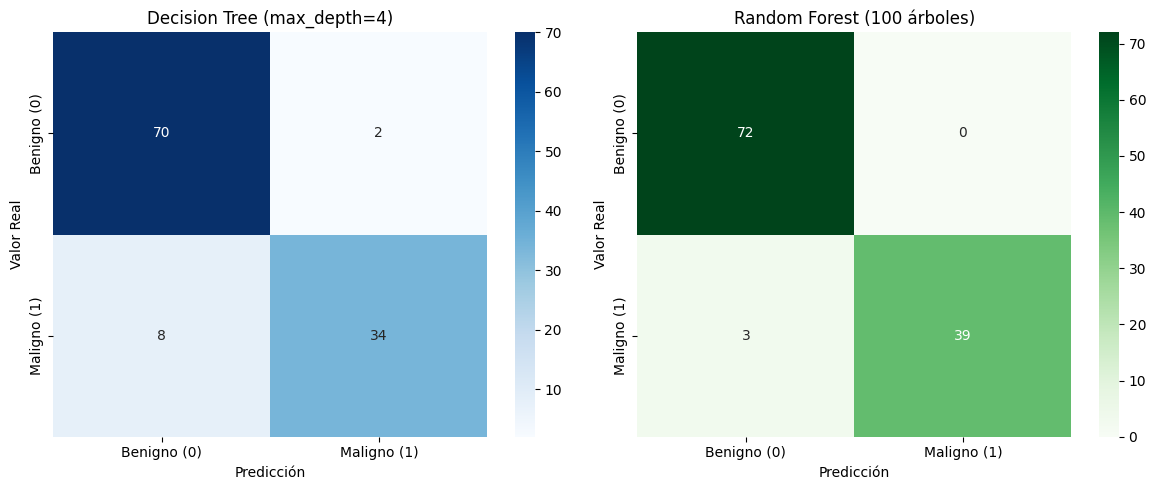

In [5]:
##Aplicación de la predicción y añadir el resultado del ejercicio en el array
modelo_rf = RandomForestClassifier(n_estimators=100, random_state=42)
resultados_totales.append(evaluar_modelo("Random Forest", modelo_rf, X_train, y_train, X_test, y_test))

pred_dt = modelo_dt.predict(X_test)
pred_rf = modelo_rf.predict(X_test)

cm_dt = confusion_matrix(y_test, pred_dt)
cm_rf = confusion_matrix(y_test, pred_rf)

#Se crea una tabla comparativa para visualizar más fácilmente los resultados obtenidos y comparar diferencias
df_comparativa = pd.DataFrame([
    {
        'Modelo': 'Decision Tree',
        'Accuracy': accuracy_score(y_test, pred_dt),
        'Precision': precision_score(y_test, pred_dt),
        'Recall': recall_score(y_test, pred_dt),
        'F1-Score': f1_score(y_test, pred_dt),
        'FP (Falsos Positivos)': cm_dt[0, 1],
        'FN (Falsos Negativos)': cm_dt[1, 0]
    },
    {
        'Modelo': 'Random Forest',
        'Accuracy': accuracy_score(y_test, pred_rf),
        'Precision': precision_score(y_test, pred_rf),
        'Recall': recall_score(y_test, pred_rf),
        'F1-Score': f1_score(y_test, pred_rf),
        'FP (Falsos Positivos)': cm_rf[0, 1],
        'FN (Falsos Negativos)': cm_rf[1, 0]
    }
])

print("TABLA COMPARATIVA: DECISION TREE VS RANDOM FOREST")
display(df_comparativa)

# Se grafican las matrices de cada algoritmo
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Matriz Decision Tree
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Benigno (0)', 'Maligno (1)'],
            yticklabels=['Benigno (0)', 'Maligno (1)'])
axes[0].set_title('Decision Tree (max_depth=4)')
axes[0].set_xlabel('Predicción')
axes[0].set_ylabel('Valor Real')

# Matriz Random Forest
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens', ax=axes[1],
            xticklabels=['Benigno (0)', 'Maligno (1)'],
            yticklabels=['Benigno (0)', 'Maligno (1)'])
axes[1].set_title('Random Forest (100 árboles)')
axes[1].set_xlabel('Predicción')
axes[1].set_ylabel('Valor Real')

plt.tight_layout()
plt.show()



## Preguntas del análisis - Ejercicio 3
1. ¿Qué cambia al pasar de un árbol individual a un conjunto de árboles?
   Respuesta: Se pasa de un único estimador a una técnica que promedia
   las predicciones de 100 árboles. Esto reduce la varianza y suaviza los sesgos individuales.

2. ¿Mejora alguna métrica? ¿Cuál y cuánto?
   Respuesta: Sí. La Precision aumenta aproximadamente un 6% y la Accuracy sube a 97.36%.
   Reduce los falsos positivos en comparación con un solo árbol (algoritmo 1).

## Ejercicio 4-Support Vector Machine (SVM)
En este ejercicio se aplicará el algoritmo SVM. SVM es sensible a la escala de las variables. Se utilizará un Pipeline para estandarizar los datos antes de
entrenar el clasificador.


=== SVM ===
Matriz de Confusión [TN, FP / FN, TP]:
[[72  0]
 [ 3 39]]
------------------------------
=== TABLA COMPARATIVA: ÁRBOLES VS SUPPORT VECTOR MACHINE (SVM) ===


,Modelo,Accuracy,Precision,Recall,F1-Score,FP (Falsos Positivos),FN (Falsos Negativos)
0,Decision Tree,0.912281,0.944444,0.809524,0.871795,2,8
1,Random Forest,0.973684,1.000000,0.928571,0.962963,0,3
2,SVM (con Escalado),0.973684,1.000000,0.928571,0.962963,0,3


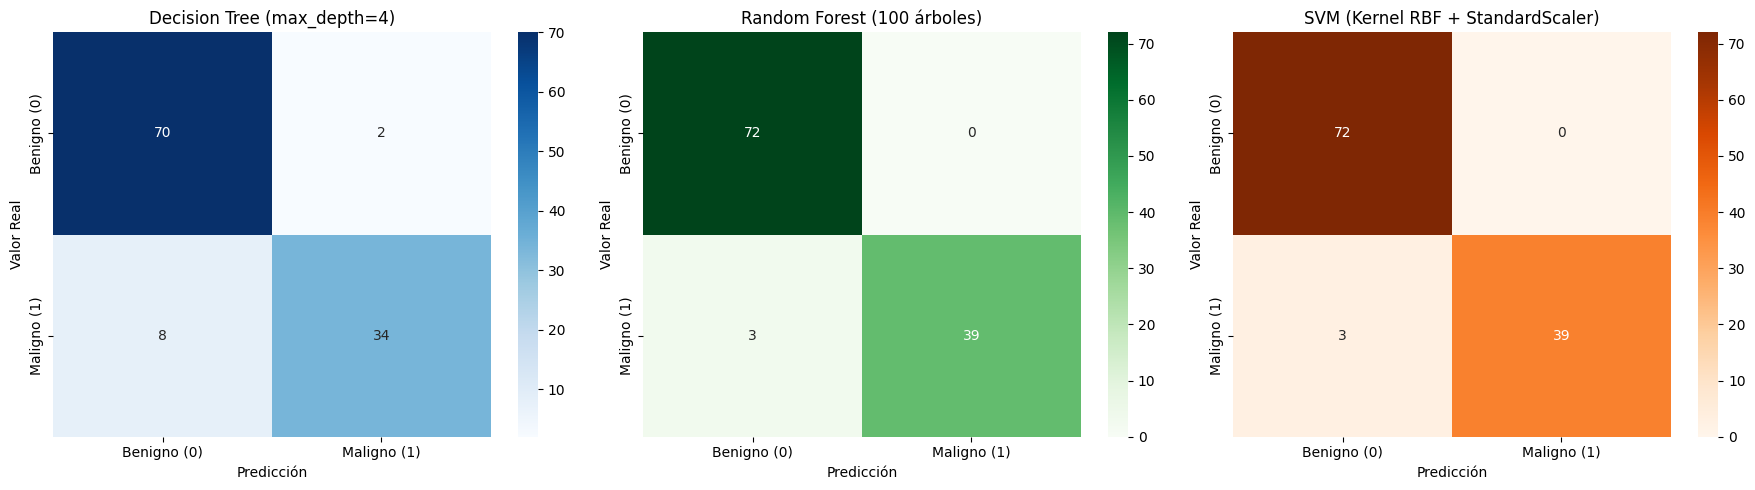

In [6]:
#Entrenamiento del modelo y se añaden los resultados al array de resultados totales
modelo_svm = make_pipeline(
    StandardScaler(),
    SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42)
)
resultados_totales.append(evaluar_modelo("SVM", modelo_svm, X_train, y_train, X_test, y_test))

# Se obtienen predicciones y se genera la matriz de confusión
pred_dt = modelo_dt.predict(X_test)
pred_rf = modelo_rf.predict(X_test)
pred_svm = modelo_svm.predict(X_test)

cm_dt = confusion_matrix(y_test, pred_dt)
cm_rf = confusion_matrix(y_test, pred_rf)
cm_svm = confusion_matrix(y_test, pred_svm)

#Se genera la tabla comparativa entre los 3 algoritmos
df_comp_ej4 = pd.DataFrame([
    {
        'Modelo': 'Decision Tree',
        'Accuracy': accuracy_score(y_test, pred_dt),
        'Precision': precision_score(y_test, pred_dt),
        'Recall': recall_score(y_test, pred_dt),
        'F1-Score': f1_score(y_test, pred_dt),
        'FP (Falsos Positivos)': cm_dt[0, 1],
        'FN (Falsos Negativos)': cm_dt[1, 0]
    },
    {
        'Modelo': 'Random Forest',
        'Accuracy': accuracy_score(y_test, pred_rf),
        'Precision': precision_score(y_test, pred_rf),
        'Recall': recall_score(y_test, pred_rf),
        'F1-Score': f1_score(y_test, pred_rf),
        'FP (Falsos Positivos)': cm_rf[0, 1],
        'FN (Falsos Negativos)': cm_rf[1, 0]
    },
    {
        'Modelo': 'SVM (con Escalado)',
        'Accuracy': accuracy_score(y_test, pred_svm),
        'Precision': precision_score(y_test, pred_svm),
        'Recall': recall_score(y_test, pred_svm),
        'F1-Score': f1_score(y_test, pred_svm),
        'FP (Falsos Positivos)': cm_svm[0, 1],
        'FN (Falsos Negativos)': cm_svm[1, 0]
    }
])

print("TABLA COMPARATIVA: ÁRBOLES VS SUPPORT VECTOR MACHINE (SVM)")
display(df_comp_ej4)

# Se grafican las matrices de confusión de los 3 resultados
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Decision Tree
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Benigno (0)', 'Maligno (1)'],
            yticklabels=['Benigno (0)', 'Maligno (1)'])
axes[0].set_title('Decision Tree (max_depth=4)')
axes[0].set_xlabel('Predicción')
axes[0].set_ylabel('Valor Real')

# Random Forest
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens', ax=axes[1],
            xticklabels=['Benigno (0)', 'Maligno (1)'],
            yticklabels=['Benigno (0)', 'Maligno (1)'])
axes[1].set_title('Random Forest (100 árboles)')
axes[1].set_xlabel('Predicción')
axes[1].set_ylabel('Valor Real')

# SVM
sns.heatmap(cm_svm, annot=True, fmt='d', cmap='Oranges', ax=axes[2],
            xticklabels=['Benigno (0)', 'Maligno (1)'],
            yticklabels=['Benigno (0)', 'Maligno (1)'])
axes[2].set_title('SVM (Kernel RBF + StandardScaler)')
axes[2].set_xlabel('Predicción')
axes[2].set_ylabel('Valor Real')

plt.tight_layout()
plt.show()

## Preguntas del análisis - Ejercicio 4
1. ¿Por qué en este modelo usamos StandardScaler?
   Respuesta: Se usa StandardScales para escalar los datos para que todas las variables tengan el mismo peso visual y matemático al momento de calcular las distancias, garantizando que el modelo sea justo y preciso.

2. ¿Qué resultado obtiene SVM frente a los modelos basados en árboles?
   Respuesta: Supera a los árboles de decisión; pero continúa en el mismo nivel de resultados que el algoritmo Random Forest.

 ## Ejercicio 5- K-Nearest Neighbors (K-NN)
 En este ejercicio se implementará el algoritmo K-NN. Se usará k=5

=== K-NN ===
Matriz de Confusión [TN, FP / FN, TP]:
[[71  1]
 [ 4 38]]
------------------------------
=== TABLA COMPARATIVA: MODELOS HASTA K-NN (EJERCICIO 5) ===


,Modelo,Accuracy,Precision,Recall,F1-Score,FP (Falsos Positivos),FN (Falsos Negativos)
0,Decision Tree,0.912281,0.944444,0.809524,0.871795,2,8
1,Random Forest,0.973684,1.000000,0.928571,0.962963,0,3
2,SVM (con Escalado),0.973684,1.000000,0.928571,0.962963,0,3
3,"K-NN (k=5, con Escalado)",0.956140,0.974359,0.904762,0.938272,1,4


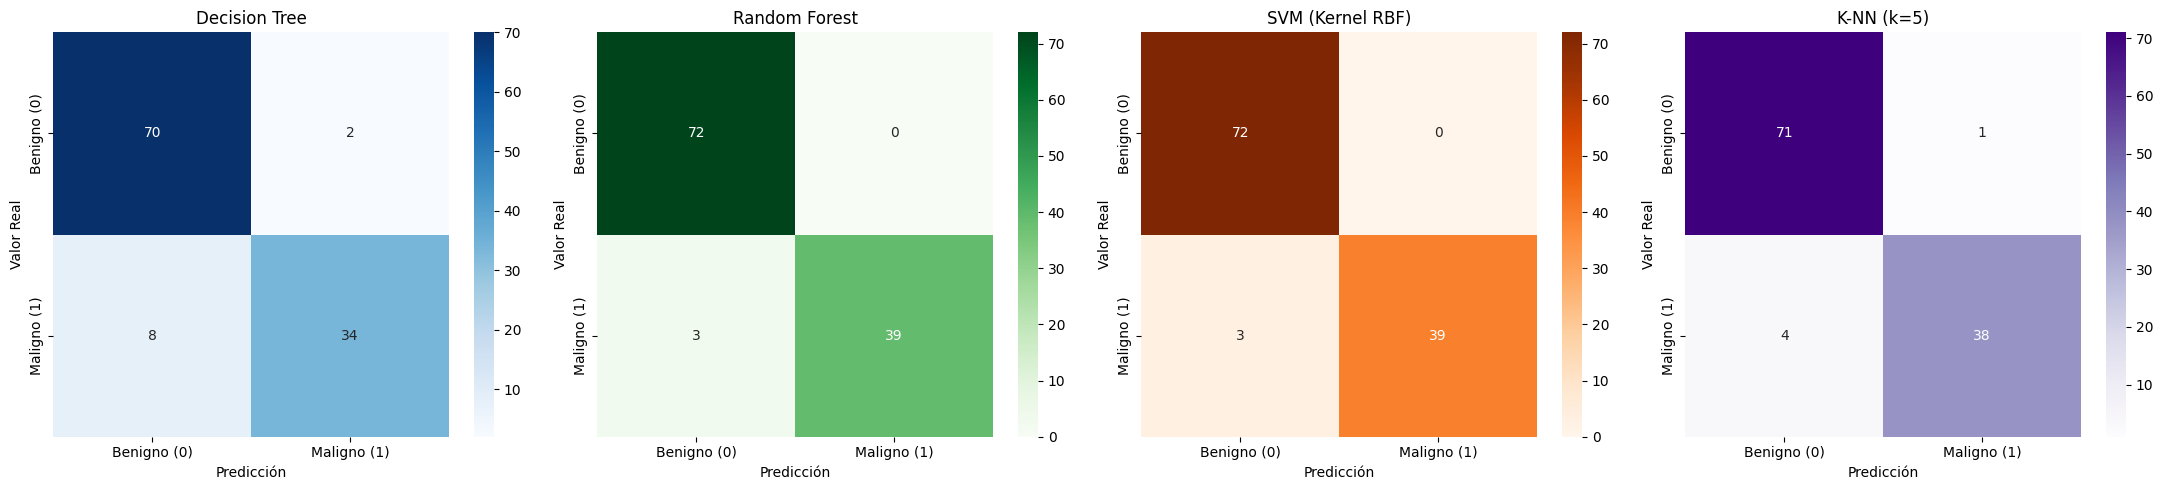

In [7]:
#Se crea el pipeline
modelo_knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)
resultados_totales.append(evaluar_modelo("K-NN", modelo_knn, X_train, y_train, X_test, y_test))

#Se obtienen las predicciones y matricess de confusión
pred_dt = modelo_dt.predict(X_test)
pred_rf = modelo_rf.predict(X_test)
pred_svm = modelo_svm.predict(X_test)
pred_knn = modelo_knn.predict(X_test)

cm_dt = confusion_matrix(y_test, pred_dt)
cm_rf = confusion_matrix(y_test, pred_rf)
cm_svm = confusion_matrix(y_test, pred_svm)
cm_knn = confusion_matrix(y_test, pred_knn)

#Se genera la tabla comparativa con los 4 modelos
df_comp_ej5 = pd.DataFrame([
    {
        'Modelo': 'Decision Tree',
        'Accuracy': accuracy_score(y_test, pred_dt),
        'Precision': precision_score(y_test, pred_dt),
        'Recall': recall_score(y_test, pred_dt),
        'F1-Score': f1_score(y_test, pred_dt),
        'FP (Falsos Positivos)': cm_dt[0, 1],
        'FN (Falsos Negativos)': cm_dt[1, 0]
    },
    {
        'Modelo': 'Random Forest',
        'Accuracy': accuracy_score(y_test, pred_rf),
        'Precision': precision_score(y_test, pred_rf),
        'Recall': recall_score(y_test, pred_rf),
        'F1-Score': f1_score(y_test, pred_rf),
        'FP (Falsos Positivos)': cm_rf[0, 1],
        'FN (Falsos Negativos)': cm_rf[1, 0]
    },
    {
        'Modelo': 'SVM (con Escalado)',
        'Accuracy': accuracy_score(y_test, pred_svm),
        'Precision': precision_score(y_test, pred_svm),
        'Recall': recall_score(y_test, pred_svm),
        'F1-Score': f1_score(y_test, pred_svm),
        'FP (Falsos Positivos)': cm_svm[0, 1],
        'FN (Falsos Negativos)': cm_svm[1, 0]
    },
    {
        'Modelo': 'K-NN (k=5, con Escalado)',
        'Accuracy': accuracy_score(y_test, pred_knn),
        'Precision': precision_score(y_test, pred_knn),
        'Recall': recall_score(y_test, pred_knn),
        'F1-Score': f1_score(y_test, pred_knn),
        'FP (Falsos Positivos)': cm_knn[0, 1],
        'FN (Falsos Negativos)': cm_knn[1, 0]
    }
])

print("TABLA COMPARATIVA: MODELOS HASTA K-NN (EJERCICIO 5)")
display(df_comp_ej5)

# Se grafican las matrices de confusión de los 4 modelos
fig, axes = plt.subplots(1, 4, figsize=(22, 5))

# Decision Tree
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Benigno (0)', 'Maligno (1)'],
            yticklabels=['Benigno (0)', 'Maligno (1)'])
axes[0].set_title('Decision Tree')
axes[0].set_xlabel('Predicción')
axes[0].set_ylabel('Valor Real')

# Random Forest
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens', ax=axes[1],
            xticklabels=['Benigno (0)', 'Maligno (1)'],
            yticklabels=['Benigno (0)', 'Maligno (1)'])
axes[1].set_title('Random Forest')
axes[1].set_xlabel('Predicción')
axes[1].set_ylabel('Valor Real')

# SVM
sns.heatmap(cm_svm, annot=True, fmt='d', cmap='Oranges', ax=axes[2],
            xticklabels=['Benigno (0)', 'Maligno (1)'],
            yticklabels=['Benigno (0)', 'Maligno (1)'])
axes[2].set_title('SVM (Kernel RBF)')
axes[2].set_xlabel('Predicción')
axes[2].set_ylabel('Valor Real')

# K-NN
sns.heatmap(cm_knn, annot=True, fmt='d', cmap='Purples', ax=axes[3],
            xticklabels=['Benigno (0)', 'Maligno (1)'],
            yticklabels=['Benigno (0)', 'Maligno (1)'])
axes[3].set_title('K-NN (k=5)')
axes[3].set_xlabel('Predicción')
axes[3].set_ylabel('Valor Real')

plt.tight_layout()
plt.show()

## Preguntas del análisis - Ejercicio 5
1. ¿Qué representa k=5 en este algoritmo?
   Respuesta: Representa el número de vecinos más cercanos en el espacio de características
   escalado que el algoritmo consulta para votar por la clase mayoritaria al predecir.

2. ¿Por qué el escalamiento es especialmente importante cuando se calculan distancias?
   Respuesta: Se genera escalamiento para normalizar las magnitudes. Así garantizamos que ninguna variable distorsione la métrica de distancia y que todas aporten información de manera justa al modelo.
  
## Ejercicio 6-Naive Bayes
Para este ejercicio, se aplicará el algoritmo Naive Bayes, donde no se usará escalamiento.

=== Naive Bayes ===
Matriz de Confusión [TN, FP / FN, TP]:
[[72  0]
 [ 7 35]]
------------------------------
=== TABLA COMPARATIVA CONSOLIDADA: 5 MODELOS CLASIFICADORES ===


,Modelo,Accuracy,Precision,Recall,F1-Score,FP (Falsos Positivos),FN (Falsos Negativos)
0,Decision Tree,0.912281,0.944444,0.809524,0.871795,2,8
1,Random Forest,0.973684,1.000000,0.928571,0.962963,0,3
2,SVM (con Escalado),0.973684,1.000000,0.928571,0.962963,0,3
3,"K-NN (k=5, con Escalado)",0.956140,0.974359,0.904762,0.938272,1,4
4,Naive Bayes (GaussianNB),0.938596,1.000000,0.833333,0.909091,0,7


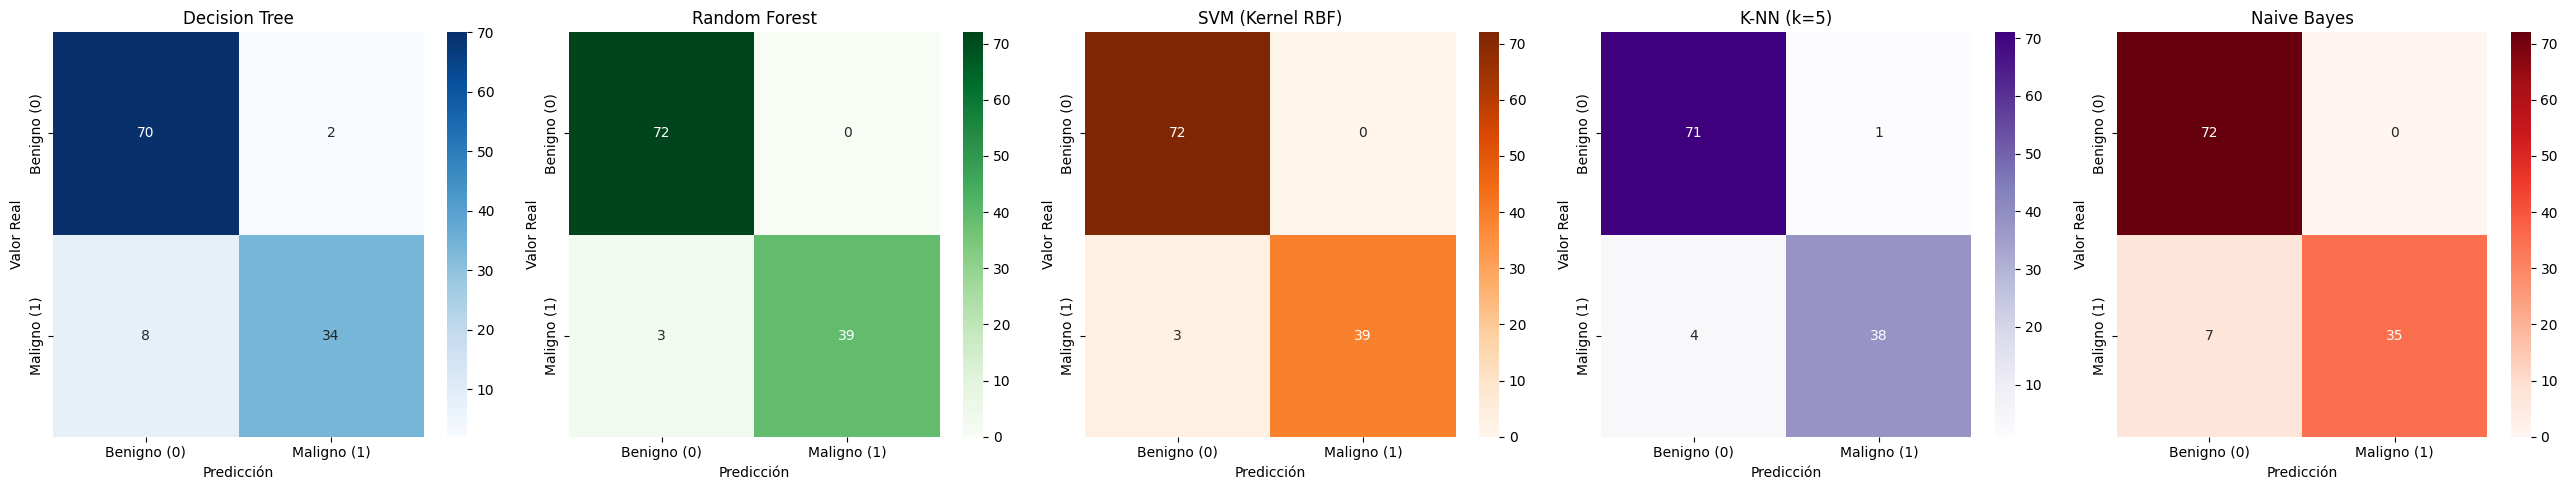

In [8]:
modelo_nb = GaussianNB()
resultados_totales.append(evaluar_modelo("Naive Bayes", modelo_nb, X_train, y_train, X_test, y_test))

# Predicciones de los 5 modelos
pred_dt = modelo_dt.predict(X_test)
pred_rf = modelo_rf.predict(X_test)
pred_svm = modelo_svm.predict(X_test)
pred_knn = modelo_knn.predict(X_test)
pred_nb = modelo_nb.predict(X_test)

#Se generan las matrices de confusión

cm_dt = confusion_matrix(y_test, pred_dt)
cm_rf = confusion_matrix(y_test, pred_rf)
cm_svm = confusion_matrix(y_test, pred_svm)
cm_knn = confusion_matrix(y_test, pred_knn)
cm_nb = confusion_matrix(y_test, pred_nb)

# Tabla comparativa completa
df_comp_ej6 = pd.DataFrame([
    {
        'Modelo': 'Decision Tree',
        'Accuracy': accuracy_score(y_test, pred_dt),
        'Precision': precision_score(y_test, pred_dt),
        'Recall': recall_score(y_test, pred_dt),
        'F1-Score': f1_score(y_test, pred_dt),
        'FP (Falsos Positivos)': cm_dt[0, 1],
        'FN (Falsos Negativos)': cm_dt[1, 0]
    },
    {
        'Modelo': 'Random Forest',
        'Accuracy': accuracy_score(y_test, pred_rf),
        'Precision': precision_score(y_test, pred_rf),
        'Recall': recall_score(y_test, pred_rf),
        'F1-Score': f1_score(y_test, pred_rf),
        'FP (Falsos Positivos)': cm_rf[0, 1],
        'FN (Falsos Negativos)': cm_rf[1, 0]
    },
    {
        'Modelo': 'SVM (con Escalado)',
        'Accuracy': accuracy_score(y_test, pred_svm),
        'Precision': precision_score(y_test, pred_svm),
        'Recall': recall_score(y_test, pred_svm),
        'F1-Score': f1_score(y_test, pred_svm),
        'FP (Falsos Positivos)': cm_svm[0, 1],
        'FN (Falsos Negativos)': cm_svm[1, 0]
    },
    {
        'Modelo': 'K-NN (k=5, con Escalado)',
        'Accuracy': accuracy_score(y_test, pred_knn),
        'Precision': precision_score(y_test, pred_knn),
        'Recall': recall_score(y_test, pred_knn),
        'F1-Score': f1_score(y_test, pred_knn),
        'FP (Falsos Positivos)': cm_knn[0, 1],
        'FN (Falsos Negativos)': cm_knn[1, 0]
    },
    {
        'Modelo': 'Naive Bayes (GaussianNB)',
        'Accuracy': accuracy_score(y_test, pred_nb),
        'Precision': precision_score(y_test, pred_nb),
        'Recall': recall_score(y_test, pred_nb),
        'F1-Score': f1_score(y_test, pred_nb),
        'FP (Falsos Positivos)': cm_nb[0, 1],
        'FN (Falsos Negativos)': cm_nb[1, 0]
    }
])

print("TABLA COMPARATIVA CONSOLIDADA")
display(df_comp_ej6)

# Gráfico de matrices de confusión para los 5 modelos
fig, axes = plt.subplots(1, 5, figsize=(26, 5))

sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Benigno (0)', 'Maligno (1)'], yticklabels=['Benigno (0)', 'Maligno (1)'])
axes[0].set_title('Decision Tree')
axes[0].set_xlabel('Predicción')
axes[0].set_ylabel('Valor Real')

sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens', ax=axes[1],
            xticklabels=['Benigno (0)', 'Maligno (1)'], yticklabels=['Benigno (0)', 'Maligno (1)'])
axes[1].set_title('Random Forest')
axes[1].set_xlabel('Predicción')
axes[1].set_ylabel('Valor Real')

sns.heatmap(cm_svm, annot=True, fmt='d', cmap='Oranges', ax=axes[2],
            xticklabels=['Benigno (0)', 'Maligno (1)'], yticklabels=['Benigno (0)', 'Maligno (1)'])
axes[2].set_title('SVM (Kernel RBF)')
axes[2].set_xlabel('Predicción')
axes[2].set_ylabel('Valor Real')

sns.heatmap(cm_knn, annot=True, fmt='d', cmap='Purples', ax=axes[3],
            xticklabels=['Benigno (0)', 'Maligno (1)'], yticklabels=['Benigno (0)', 'Maligno (1)'])
axes[3].set_title('K-NN (k=5)')
axes[3].set_xlabel('Predicción')
axes[3].set_ylabel('Valor Real')

sns.heatmap(cm_nb, annot=True, fmt='d', cmap='Reds', ax=axes[4],
            xticklabels=['Benigno (0)', 'Maligno (1)'], yticklabels=['Benigno (0)', 'Maligno (1)'])
axes[4].set_title('Naive Bayes')
axes[4].set_xlabel('Predicción')
axes[4].set_ylabel('Valor Real')

plt.tight_layout()
plt.show()

## Preguntas del análisis - Ejercicio 6
1. ¿Qué supuesto simplificador utiliza Naive Bayes respecto a las variables?
   Respuesta: Asume independencia condicional completa entre todas las variables independientes
   dada la clase.

2. ¿En qué métricas se comporta mejor o peor que los otros clasificadores?
   Respuesta:
   - Dónde se comportó mejor: Obtuvo una Precision perfecta de 1.000000 (100%), registrando
     0 Falsos Positivos (empatado en este aspecto con Random Forest y SVM).
   - Dónde se comportó peor: Obtuvo un Recall bajo del 0.833333 (83.33%), generado por acumular
     7 Falsos Negativos (casos no detectados), superando únicamente al Árbol de Decisión
     individual (que tuvo 8 FN) y quedando muy por detrás de Random Forest y SVM (que tuvieron solo 3 FN).
   - Desempeño general: Su Accuracy (93.86%) y F1-Score (0.9090) se ubican en una posición intermedia,
     por debajo de Random Forest, SVM y K-NN.
